## Concrete Strength Prediction & Deployment
## A hands-on machine learning project for Meridian Ready-Mix. 

---
    
## 🏢 The Company
** Meridian Ready-Mix ** supplies concrete to commercial construction sites. The data is the Concrete Compressive Strength dataset published through the UCI 
Machine Learning Repository: 1,030 laboratory tests recording eight mix quantities and the 
strength measured afterwards, from I-Cheng Yeh's 1998 study.


##❗ The Business Problem
Concrete is certified by crushing a sample after 28 days of curing. A proposed mix 
therefore cannot be signed off for a month, so the laboratory hedges: it adds cement, 
the most expensive ingredient in the mix and the largest part of its carbon footprint, to 
be confident the sample will pass. Nobody knows how much of that cement was 
actually needed.

How to turn a 28-day laboratory wait into a same-day screen.

    
## 🎯 Your Role
You are the lead machine learning developer. You will:

1. Clean the longitudinal concrete strength data
2. Build a reusable preprocessing + modelling pipeline
3. Train a model that flags low strength conrete in a day
4. Explain the root drivers of dropout
5. predict 28-day compressive strength from the mix alone, then use the model to propose a cheaper recipe that still reaches the strength specified
    • How is strength distributed, and is it skewed?
    • Which single ingredient predicts strength best on its own?
    • How does strength grow with curing age? Is it a straight line?
    • Does the water-to-cement ratio beat either one alone?
    • How far does a linear model get before it stalls?
    • Which mixes does your model get worst, and what links them?
    • What is the cheapest mix that still reaches 40 MPa?
    
## 🗺️ Project Roadmap
| Step | What we do | Key skill |
|---|---|---|
| 0 | Setup | Libraries |
| 1 | Load, explore & clean data | pandas |
| 2 | Spot early-warning signals (EDA) | Visual storytelling |
| 3 | Split data **safely** | Avoiding data leakage |
| 4 | Build the preprocessing pipeline | `ColumnTransformer` |
| 5 | Train the model (class weighting) | Imbalanced classification |
| 6 | Evaluate the model | Precision, recall, ROC-AUC |
| 7 | Make probabilities trustworthy | Calibration |
| 8 | Explain the model | Feature importance |
| 9 | Turn scores into action | Risk tiers & fairness check |
| 10 | Save & deploy with Gradio | Deployment |

## Step 0 import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import streamlit as st
from sklearn.preprocessing import StandardScaler, OneHotEncoder


import warnings
warnings.filterwarnings("ignore")          # ignore any warning across the code

## Step 1: Data exploration and cleaning


In [2]:
data = pd.read_csv("concrete_strength.csv")

In [3]:
data.head()

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days,compressive_strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## Cement_kg_m3 is Portland cement the costly ingredient can also refer to the cement id
## This can be classified as a longitudunal dataset

note: blast furnance slag(steel by product) partial replaces the cement and fly ash (coal ash) replaces cement

In [4]:
rows_per_cement_id= data.groupby("cement_kg_m3").size()
rows_per_cement_id

cement_kg_m3
102.0    4
108.3    4
116.0    4
122.6    4
132.0    2
        ..
522.0    2
525.0    7
528.0    1
531.3    5
540.0    9
Length: 278, dtype: int64

In [5]:
print(f"Unique cement id : {data['cement_kg_m3'].nunique():,}")
print(f"Total rows      : {len(data):,}")
print(f"Rows per cement id: min={rows_per_cement_id.min()}, average={rows_per_cement_id.mean():.1f}, max={rows_per_cement_id.max()}")

Unique cement id : 278
Total rows      : 1,030
Rows per cement id: min=1, average=3.7, max=20


In [6]:
rows_per_cement_age_days= data.groupby("age_days").size()
rows_per_cement_age_days

age_days
1        2
3      134
7      126
14      62
28     425
56      91
90      54
91      22
100     52
120      3
180     26
270     13
360      6
365     14
dtype: int64

In [7]:
rows_per_cement_strength= data.groupby("compressive_strength_mpa").size()
rows_per_cement_strength

compressive_strength_mpa
2.33     1
3.32     1
4.57     1
4.78     1
4.83     1
        ..
79.40    1
79.99    1
80.20    1
81.75    1
82.60    1
Length: 845, dtype: int64

In [8]:
print(f"Unique cement strength : {data['compressive_strength_mpa'].nunique():,}")
print(f"Total rows      : {len(data):,}")
print(f"Rows per cement strength: min={rows_per_cement_strength.min()}, average={rows_per_cement_strength.mean():.1f}, max={rows_per_cement_strength.max()}")

Unique cement strength : 845
Total rows      : 1,030
Rows per cement strength: min=1, average=1.2, max=6


In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   cement_kg_m3              1030 non-null   float64
 1   blast_furnace_slag_kg_m3  1030 non-null   float64
 2   fly_ash_kg_m3             1030 non-null   float64
 3   water_kg_m3               1030 non-null   float64
 4   superplasticizer_kg_m3    1030 non-null   float64
 5   coarse_aggregate_kg_m3    1030 non-null   float64
 6   fine_aggregate_kg_m3      1030 non-null   float64
 7   age_days                  1030 non-null   int64  
 8   compressive_strength_mpa  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


### Confirm no missing values

In [10]:
missing = data.isna().sum()
missing_report = pd.DataFrame({"missing_count": missing, "missing_%": (missing / len(data) * 100).round(2)})
missing_report[missing_report["missing_count"] > 0]

,missing_count,missing_%


<Axes: >

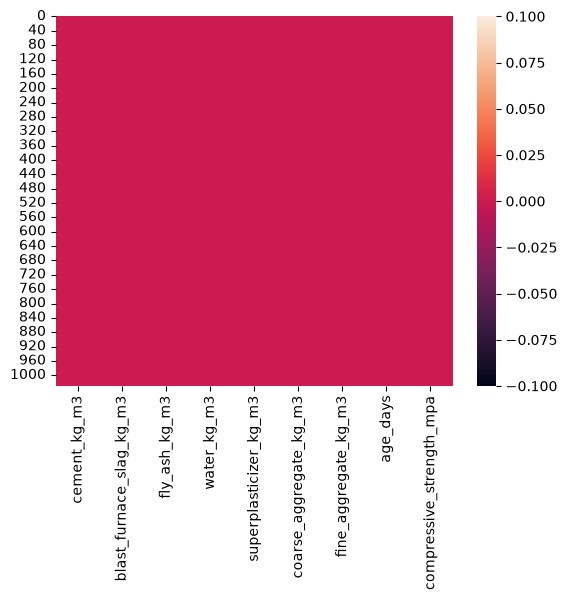

In [11]:
sns.heatmap(data.isnull())

## Looking at the target crush strength of 40Mpa and above with a 28 day curing age

Our target (y) is compressive strength greater than 40Mpa: 1 = acceptable, 0 = unacceptable.

In [12]:
X = data.drop(columns=['compressive_strength_mpa'])
y = data['compressive_strength_mpa'].to_numpy()

data["target_y"] = np.where(y > 40, 1, 0)

print(data["target_y"])

0       1
1       1
2       1
3       1
4       1
       ..
1025    1
1026    0
1027    0
1028    0
1029    0
Name: target_y, Length: 1030, dtype: int64


In [13]:
target_counts = data["target_y"].value_counts().sort_index()
target_pct = data["target_y"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)}))


          count  percent
target_y                
0           651     63.2
1           379     36.8


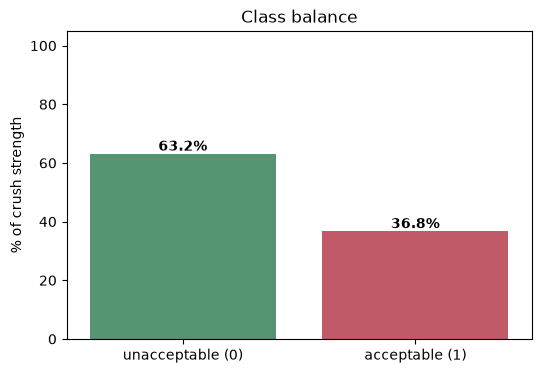

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["unacceptable (0)", "acceptable (1)"], y=target_pct.values, palette=["#4C9F70", "#D1495B"], ax=ax)
for i, v in enumerate(target_pct.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set_ylabel("% of crush strength"); ax.set_title("Class balance"); ax.set_ylim(0, 105)
plt.show()

## Duplicates

In [15]:
data.duplicated().sum()

np.int64(25)

In [16]:
duplicates = data[data.duplicated(keep=False)]
print(duplicates.sort_values(by=list(data.columns)))

     cement_kg_m3  blast_furnace_slag_kg_m3  fly_ash_kg_m3  water_kg_m3  \
801         252.0                       0.0            0.0        185.0   
809         252.0                       0.0            0.0        185.0   
83          362.6                     189.0            0.0        164.9   
86          362.6                     189.0            0.0        164.9   
88          362.6                     189.0            0.0        164.9   
91          362.6                     189.0            0.0        164.9   
106         362.6                     189.0            0.0        164.9   
109         362.6                     189.0            0.0        164.9   
111         362.6                     189.0            0.0        164.9   
129         362.6                     189.0            0.0        164.9   
132         362.6                     189.0            0.0        164.9   
134         362.6                     189.0            0.0        164.9   
137         362.6        

In [17]:
data =  data.drop_duplicates()
print("New row count:", len(data))

New row count: 1005


In [18]:
data.describe()

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days,compressive_strength_mpa,target_y
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.631343,72.043483,55.536318,182.075323,6.033234,974.376816,772.688259,45.856716,35.250378,0.358209
std,104.344261,86.170807,64.207969,21.339334,5.919967,77.579667,80.340435,63.734692,16.284815,0.479713
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000,0.000000
25%,190.700000,0.000000,0.000000,166.600000,0.000000,932.000000,724.300000,7.000000,23.520000,0.000000
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.800000,0.000000
75%,349.000000,142.500000,118.300000,192.900000,10.000000,1031.000000,822.200000,56.000000,44.870000,1.000000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000,1.000000


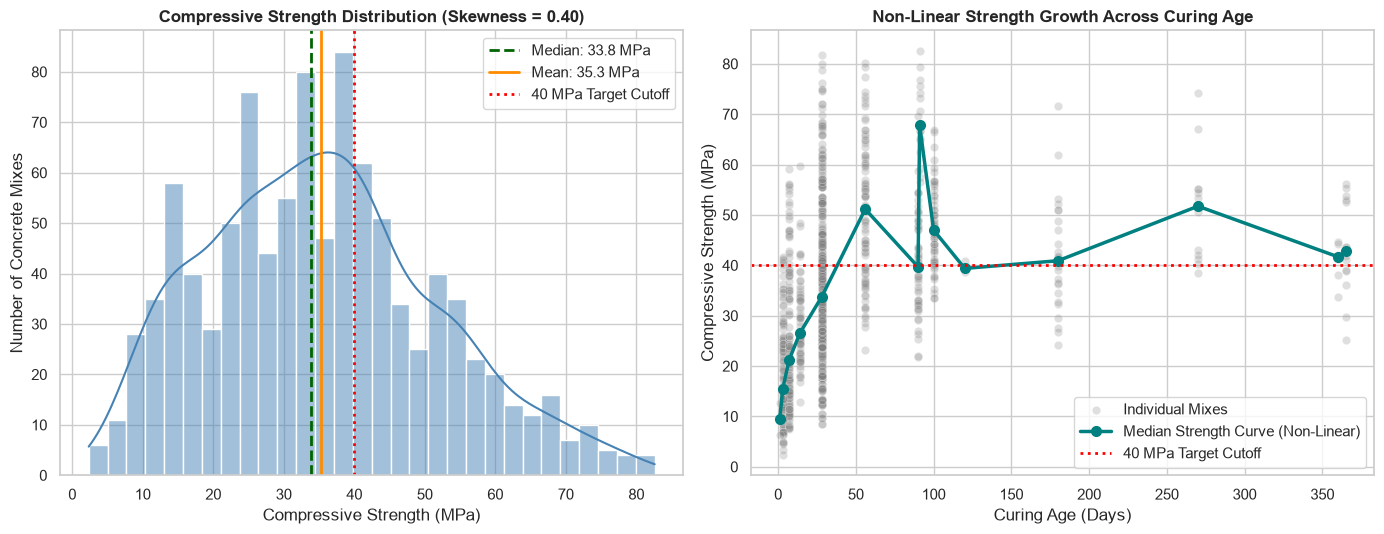

In [19]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# PLOT 1: Right-Skewed Distribution (Left)

sns.histplot(
    data['compressive_strength_mpa'],
    bins=30,
    kde=True,
    color='steelblue',
    ax=axes[0],
)

mean_val = data['compressive_strength_mpa'].mean()
median_val = data['compressive_strength_mpa'].median()
skew_val = data['compressive_strength_mpa'].skew()

# Plot vertical lines showing Mean > Median (the classic signature of right skew)
axes[0].axvline(
    median_val,
    color='darkgreen',
    linestyle='--',
    lw=2,
    label=f'Median: {median_val:.1f} MPa',
)
axes[0].axvline(
    mean_val,
    color='darkorange',
    linestyle='-',
    lw=2,
    label=f'Mean: {mean_val:.1f} MPa',
)
axes[0].axvline(
    40.0, color='red', linestyle=':', lw=2, label='40 MPa Target Cutoff'
)

axes[0].set_title(
    f'Compressive Strength Distribution (Skewness = {skew_val:.2f})',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('Compressive Strength (MPa)')
axes[0].set_ylabel('Number of Concrete Mixes')
axes[0].legend()

# PLOT 2: Non-Linear Age Growth Curve (Right)

# Plot individual mixes lightly in the background
sns.scatterplot(
    data=data,
    x='age_days',
    y='compressive_strength_mpa',
    color='gray',
    alpha=0.25,
    ax=axes[1],
    label='Individual Mixes',
)

# Plot median strength at each curing age to highlight the logarithmic curve
age_trend = data.groupby('age_days')['compressive_strength_mpa'].median()
axes[1].plot(
    age_trend.index,
    age_trend.values,
    color='teal',
    marker='o',
    lw=2.5,
    markersize=7,
    label='Median Strength Curve (Non-Linear)',
)

# Add 40 MPa reference line
axes[1].axhline(
    40.0, color='red', linestyle=':', lw=2, label='40 MPa Target Cutoff'
)

axes[1].set_title(
    'Non-Linear Strength Growth Across Curing Age',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('Curing Age (Days)')
axes[1].set_ylabel('Compressive Strength (MPa)')
axes[1].legend()

plt.tight_layout()
plt.savefig('capstone_skew_and_nonlinearity.png', dpi=300)
plt.show()


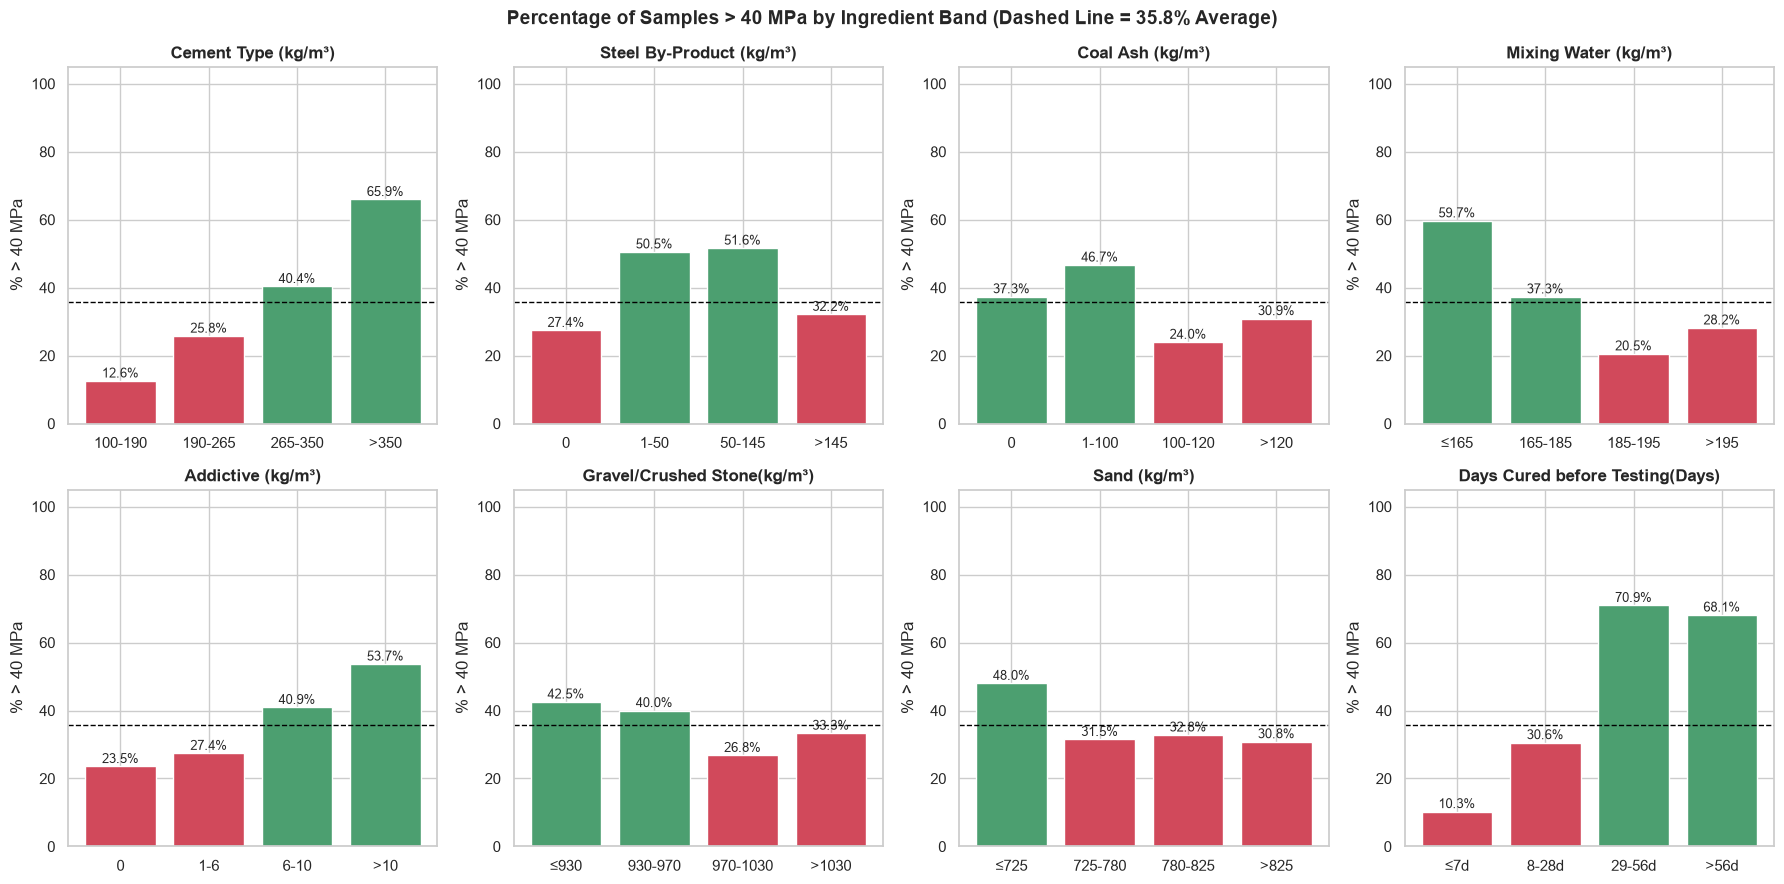

In [20]:
def compressive_strength_plot(ax, column, bins, labels, title):
    """Bar chart: % of samples > 40 MPa for each band of a numeric column."""
    bands = pd.cut(data[column], bins=bins, labels=labels)
    rate = data.groupby(bands, observed=True)["target_y"].mean() * 100
    # Note: Green (#4C9F70) if higher than overall_rate, Red (#D1495B) if lower
    colors = ["#4C9F70" if r > overall_rate else "#D1495B" for r in rate]
    ax.bar(rate.index.astype(str), rate.values, color=colors)
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("% > 40 MPa")
    ax.set_ylim(0, 105)

overall_rate = data["target_y"].mean() *  100

# Create a 2x4 grid for your 8 input features
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Row 1: Binders & Water
compressive_strength_plot(axes[0, 0], "cement_kg_m3", [100, 190, 265, 350, 550], ["100-190", "190-265", "265-350", ">350"], "Cement Type (kg/m³)")
compressive_strength_plot(axes[0, 1], "blast_furnace_slag_kg_m3", [-1, 0, 50, 145, 360], ["0", "1-50", "50-145", ">145"], "Steel By-Product (kg/m³)")
compressive_strength_plot(axes[0, 2], "fly_ash_kg_m3", [-1, 0, 100, 120, 205], ["0", "1-100", "100-120", ">120"], "Coal Ash (kg/m³)")
compressive_strength_plot(axes[0, 3], "water_kg_m3", [120, 165, 185, 195, 250], ["≤165", "165-185", "185-195", ">195"], "Mixing Water (kg/m³)")

# Row 2: Additives, Aggregates & Curing Age
compressive_strength_plot(axes[1, 0], "superplasticizer_kg_m3", [-1, 0, 6, 10, 35], ["0", "1-6", "6-10", ">10"], "Addictive (kg/m³)")
compressive_strength_plot(axes[1, 1], "coarse_aggregate_kg_m3", [800, 930, 970, 1030, 1150], ["≤930", "930-970", "970-1030", ">1030"], "Gravel/Crushed Stone(kg/m³)")
compressive_strength_plot(axes[1, 2], "fine_aggregate_kg_m3", [590, 725, 780, 825, 1000], ["≤725", "725-780", "780-825", ">825"], "Sand (kg/m³)")
compressive_strength_plot(axes[1, 3], "age_days", [0, 7, 28, 56, 370], ["≤7d", "8-28d", "29-56d", ">56d"], "Days Cured before Testing(Days)")

plt.suptitle(f"Percentage of Samples > 40 MPa by Ingredient Band (Dashed Line = {overall_rate:.1f}% Average)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## How cement, and other category relate to compression strength

Mixes with cement ≥ 265 kg/m³ AND strength > 40 MPa: 26.2% of rows
Mixes with cement < 265 kg/m³ AND strength < 40 MPa: 40.3% of rows
Mixes with cement ≥ 265, age ≥ 28 days, AND strength > 40 MPa: 23.2% of rows
Mixes with superplasticizer > 0 AND strength > 40 MPa: 27.0% of rows



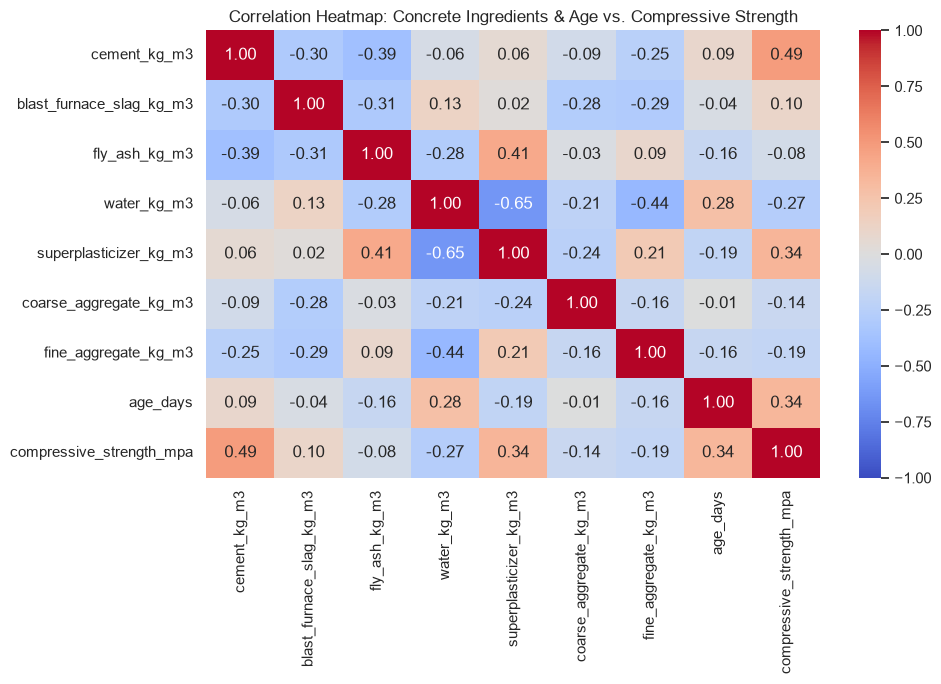

In [21]:
target_col = ('compressive_strength_mpa')
corr_cols = ["cement_kg_m3", "blast_furnace_slag_kg_m3", "fly_ash_kg_m3", "water_kg_m3", "superplasticizer_kg_m3",
             "coarse_aggregate_kg_m3", "fine_aggregate_kg_m3", "age_days"]

# High cement (>= 265 kg/m³) AND strength > 40 MPa
cond_1 = (data['cement_kg_m3'] >= 265) & (data[target_col] > 40)
print(f"Mixes with cement ≥ 265 kg/m³ AND strength > 40 MPa: {cond_1.mean()*100:.1f}% of rows")

# Low cement (< 265 kg/m³) AND strength < 40 MPa
cond_2 = (data['cement_kg_m3'] < 265) & (data[target_col] < 40)
print(f"Mixes with cement < 265 kg/m³ AND strength < 40 MPa: {cond_2.mean()*100:.1f}% of rows")

# High cement (>= 265) AND cured at least 28 days AND strength > 40 MPa
cond_3 = (data['cement_kg_m3'] >= 265) & (data['age_days'] >= 28) & (data[target_col] > 40)
print(f"Mixes with cement ≥ 265, age ≥ 28 days, AND strength > 40 MPa: {cond_3.mean()*100:.1f}% of rows")

# Using Superplasticizer (> 0) AND strength > 40 MPa
cond_4 = (data['superplasticizer_kg_m3'] > 0) & (data[target_col] > 40)
print(f"Mixes with superplasticizer > 0 AND strength > 40 MPa: {cond_4.mean()*100:.1f}% of rows\n")

plt.figure(figsize=(10, 7))
corr_matrix = data[corr_cols + [target_col]].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap: Concrete Ingredients & Age vs. Compressive Strength')
plt.tight_layout()
plt.show()



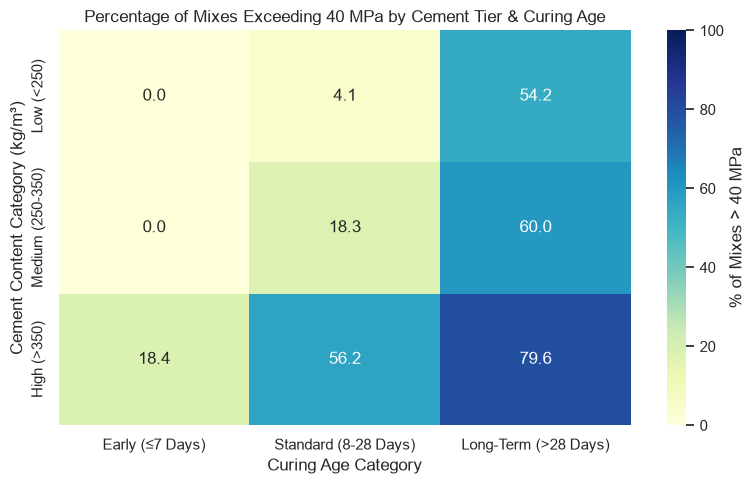

In [22]:
# Interaction Heatmap (% > 40 MPa)
# ==========================================
# Create a binary column: 1 if > 40 MPa, 0 if <= 40 MPa
data['above_40_mpa'] = (data[target_col] > 40).astype(int)

# Group cement and curing age into clean categories
data['cement_tier'] = pd.cut(
    data['cement_kg_m3'],
    bins=[0, 200, 265, float('inf')],
    labels=['Low (<250)', 'Medium (250-350)', 'High (>350)']
)

data['age_tier'] = pd.cut(
    data['age_days'],
    bins=[0, 7, 28, 400],
    labels=['Early (≤7 Days)', 'Standard (8-28 Days)', 'Long-Term (>28 Days)']
)

# Calculate percentage of mixes > 40 MPa for each combination
heatmap_pct = pd.crosstab(
    index=data['cement_tier'],
    columns=data['age_tier'],
    values=data['above_40_mpa'],
    aggfunc='mean'
) * 100

plt.figure(figsize=(8, 5))
sns.heatmap(
    heatmap_pct,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    vmin=0,
    vmax=100,
    cbar_kws={'label': '% of Mixes > 40 MPa'}
)
plt.title('Percentage of Mixes Exceeding 40 MPa by Cement Tier & Curing Age')
plt.xlabel('Curing Age Category')
plt.ylabel('Cement Content Category (kg/m³)')
plt.tight_layout()
plt.show()

## Building Machine Learning Model

In [23]:
data.head()

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days,compressive_strength_mpa,target_y,above_40_mpa,cement_tier,age_tier
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,1,1,High (>350),Standard (8-28 Days)
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,1,1,High (>350),Standard (8-28 Days)
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,1,1,High (>350),Long-Term (>28 Days)
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,1,1,High (>350),Long-Term (>28 Days)
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,1,1,Low (<250),Long-Term (>28 Days)


In [24]:
## separate the dataset into x and y

feature_cols = [
    'cement_kg_m3',
    'blast_furnace_slag_kg_m3',
    'fly_ash_kg_m3',
    'water_kg_m3',
    'superplasticizer_kg_m3',
    'coarse_aggregate_kg_m3',
    'fine_aggregate_kg_m3',
    'age_days'
]

X = data[feature_cols].copy()
y = data['compressive_strength_mpa'].copy()

y_strat = data['target_y'].copy()

print("X shape:", X.shape)         
print("y shape:", y.shape)  
print("y_strat shape:", y_strat.shape)  

X shape: (1005, 8)
y shape: (1005,)
y_strat shape: (1005,)


In [25]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

# Define groups by mix recipe (all ingredients except age_days)
mix_cols = [col for col in feature_cols if col != 'age_days']
groups = data.groupby(mix_cols).ngroup()
 
# Split data (n_splits=5 creates an 80% train / 20% test split)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(splitter.split(X, y_strat, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Training set: {X_train.shape}, Testing set: {X_test.shape}")

Training set: (803, 8), Testing set: (202, 8)


In [26]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

rmse_scores = []
r2_scores = []

# Loop through all 5 folds automatically
for fold, (train_idx, test_idx) in enumerate(splitter.split(X, y_strat, groups), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Train and predict
    model = RandomForestRegressor(random_state=42)
    model.fit(X_train, y_train)
    y_preds = model.predict(X_test)
    
    # Score this fold
    rmse = root_mean_squared_error(y_test, y_preds)
    r2 = r2_score(y_test, y_preds)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    print(f"Fold {fold} — RMSE: {rmse:.2f} MPa | R²: {r2:.3f}")

print(f"\nAverage 5-Fold RMSE: {np.mean(rmse_scores):.2f} MPa")
print(f"Average 5-Fold R²: {np.mean(r2_scores):.3f}")

Fold 1 — RMSE: 6.16 MPa | R²: 0.844
Fold 2 — RMSE: 5.60 MPa | R²: 0.879
Fold 3 — RMSE: 5.77 MPa | R²: 0.865
Fold 4 — RMSE: 5.75 MPa | R²: 0.885
Fold 5 — RMSE: 6.23 MPa | R²: 0.864

Average 5-Fold RMSE: 5.90 MPa
Average 5-Fold R²: 0.867


In [27]:
 model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

### Fold stability ranging between 0.844 to 0.885 shows that the model is stable.  The R² and RMSE values remain tightly clustered across all 5 folds (ranging from 5.60 MPa to 6.23 MPa). This confirms your model is stable and does not overfit to a lucky split of data.

In [28]:
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.base import BaseEstimator, TransformerMixin

# Define models to compare (SVR is wrapped in a Pipeline for automatic scaling)
models = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
    "Support Vector (SVR)": make_pipeline(StandardScaler(), SVR(C=10, gamma='scale'))
}
   
# Setup your existing StratifiedGroupKFold splitter
mix_cols = [col for col in feature_cols if col != 'age_days']
groups = data.groupby(mix_cols).ngroup()
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate every model across all 5 folds
for name, model in models.items():
    rmse_list, r2_list = [], []
    
    for train_idx, test_idx in splitter.split(X, y_strat, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        
        rmse_list.append(root_mean_squared_error(y_test, preds))
        r2_list.append(r2_score(y_test, preds))
        
    print(f"{name:22s} | Avg RMSE: {np.mean(rmse_list):.2f} MPa | Avg R²: {np.mean(r2_list):.3f}")

Random Forest          | Avg RMSE: 5.90 MPa | Avg R²: 0.867
Extra Trees            | Avg RMSE: 5.33 MPa | Avg R²: 0.890
HistGradientBoosting   | Avg RMSE: 5.78 MPa | Avg R²: 0.872
Support Vector (SVR)   | Avg RMSE: 7.30 MPa | Avg R²: 0.797


Tuned Extra Trees + Engineered Features | Overall RMSE: 5.22 MPa | Overall R²: 0.897


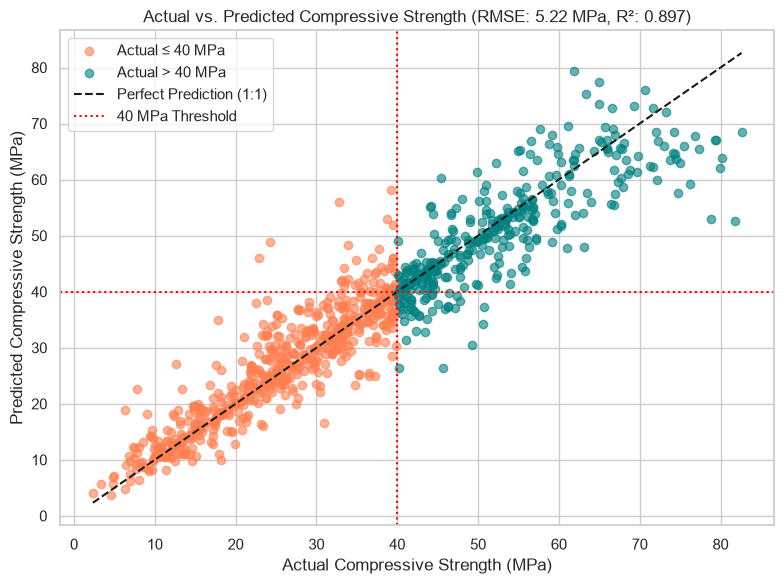

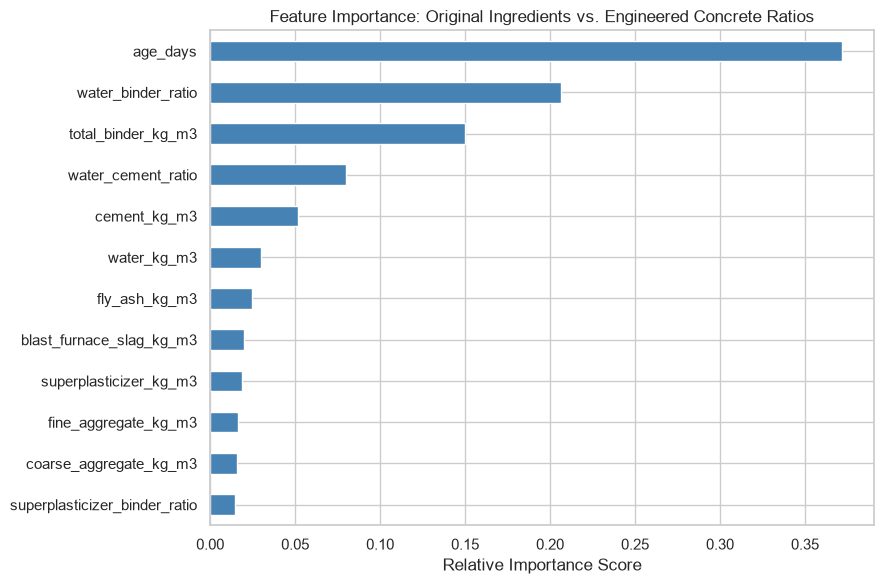

In [29]:

# copy of your features

X_eng = data[feature_cols].copy()

# Add key civil engineering concrete ratios
X_eng['total_binder_kg_m3'] = (
    X_eng['cement_kg_m3'] + 
    X_eng['blast_furnace_slag_kg_m3'] + 
    X_eng['fly_ash_kg_m3']
)
X_eng['water_cement_ratio'] = X_eng['water_kg_m3'] / X_eng['cement_kg_m3']
X_eng['water_binder_ratio'] = X_eng['water_kg_m3'] / X_eng['total_binder_kg_m3']
X_eng['superplasticizer_binder_ratio'] = X_eng['superplasticizer_kg_m3'] / X_eng['total_binder_kg_m3']


# 2. Evaluate Tuned Extra Trees (5-Fold CV)

mix_cols = [col for col in feature_cols if col != 'age_days']
groups = data.groupby(mix_cols).ngroup()
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Tuned Extra Trees model (300 trees for smoother, more stable predictions)
et_tuned = ExtraTreesRegressor(
    n_estimators=300,
    max_features= None,  # Often reduces variance on engineered tabular features; try None if RMSE rises
    random_state=42,
    n_jobs=-1
)

# Generate out-of-fold predictions for every row cleanly without data leakage
oof_preds = cross_val_predict(
    et_tuned,
    X_eng,
    y,
 groups=groups,
    cv=splitter.split(X_eng, y_strat, groups)
)

new_rmse = root_mean_squared_error(y, oof_preds)
new_r2 = r2_score(y, oof_preds)

print(f"Tuned Extra Trees + Engineered Features | Overall RMSE: {new_rmse:.2f} MPa | Overall R²: {new_r2:.3f}")


# 3. Plot Actual vs. Predicted MPa (40 MPa Target)

plt.figure(figsize=(8, 6))

# Color points by whether they truly exceed 40 MPa
above_40 = y > 40
plt.scatter(y[~above_40], oof_preds[~above_40], color='coral', alpha=0.6, label='Actual ≤ 40 MPa')
plt.scatter(y[above_40], oof_preds[above_40], color='teal', alpha=0.6, label='Actual > 40 MPa')

# Plot the ideal 1:1 prediction line and 40 MPa threshold lines
min_val, max_val = min(y.min(), oof_preds.min()), max(y.max(), oof_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=1.5, label='Perfect Prediction (1:1)')
plt.axhline(40, color='red', linestyle=':', lw=1.5, label='40 MPa Threshold')
plt.axvline(40, color='red', linestyle=':', lw=1.5)

plt.title(f'Actual vs. Predicted Compressive Strength (RMSE: {new_rmse:.2f} MPa, R²: {new_r2:.3f})')
plt.xlabel('Actual Compressive Strength (MPa)')
plt.ylabel('Predicted Compressive Strength (MPa)')
plt.legend()
plt.tight_layout()
plt.show()


# 4. Feature Importance Ranking
# Fit on the full dataset to inspect which features drive the predictions

et_tuned.fit(X_eng, y)

importances = pd.Series(et_tuned.feature_importances_, index=X_eng.columns).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
importances.plot(kind='barh', color='steelblue')
plt.title('Feature Importance: Original Ingredients vs. Engineered Concrete Ratios')
plt.xlabel('Relative Importance Score')
plt.tight_layout()
plt.show()



In [30]:
# Custom Transformer for Concrete Ratios

class ConcreteFeatureEngineer(BaseEstimator, TransformerMixin):
    """Automatically computes civil engineering ratios inside the pipeline."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        total_binder = (
            X_out['cement_kg_m3']
            + X_out['blast_furnace_slag_kg_m3']
            + X_out['fly_ash_kg_m3']
        )
        X_out['total_binder_kg_m3'] = total_binder
        # Use np.where to safely avoid division-by-zero errors
        X_out['water_cement_ratio'] = np.where(
            X_out['cement_kg_m3'] > 0,
            X_out['water_kg_m3'] / X_out['cement_kg_m3'],
            0,
        )
        X_out['water_binder_ratio'] = np.where(
            total_binder > 0, X_out['water_kg_m3'] / total_binder, 0
        )
        X_out['superplasticizer_binder_ratio'] = np.where(
            total_binder > 0, X_out['superplasticizer_kg_m3'] / total_binder, 0
        )
        return X_out

# 2. Assemble the Complete Pipeline

concrete_pipeline = Pipeline(
    steps=[
        ('feature_engineering', ConcreteFeatureEngineer()),
        (
            'regressor',
            ExtraTreesRegressor(
                n_estimators=300, max_features=None, random_state=42, n_jobs=-1
            ),
        ),
    ]
)

# 3. Validate the Pipeline (5-Fold Group CV)

feature_cols = [
    'cement_kg_m3',
    'blast_furnace_slag_kg_m3',
    'fly_ash_kg_m3',
    'water_kg_m3',
    'superplasticizer_kg_m3',
    'coarse_aggregate_kg_m3',
    'fine_aggregate_kg_m3',
    'age_days',
]

X_raw = data[feature_cols].copy()
y = data['compressive_strength_mpa'].copy()
y_strat = data['target_y'].copy()

mix_cols = [col for col in feature_cols if col != 'age_days']
groups = data.groupby(mix_cols).ngroup()
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = cross_val_predict(
    concrete_pipeline,
    X_raw,
    y,
    groups=groups,
    cv=splitter.split(X_raw, y_strat, groups),
)

print(
    f'Pipeline 5-Fold RMSE: {root_mean_squared_error(y, oof_preds):.2f} MPa |'
    f' R²: {r2_score(y, oof_preds):.3f}'
)


# 4. Fit on Full Data & Save to Disk

concrete_pipeline.fit(X_raw, y)

# Save the entire pipeline (feature logic + trained model) into one file
joblib.dump(concrete_pipeline, 'concrete_strength_pipeline.joblib')
print("Saved pipeline successfully to 'concrete_strength_pipeline.joblib'")


# 5. Predict on Raw Mix Data (No Manual Math Needed)

loaded_pipeline = joblib.load('concrete_strength_pipeline.joblib')

sample_mixes = pd.DataFrame([
      {
        'cement_kg_m3': 320,
        'blast_furnace_slag_kg_m3': 100,
        'fly_ash_kg_m3': 0,
        'water_kg_m3': 165,
        'superplasticizer_kg_m3': 6.0,
        'coarse_aggregate_kg_m3': 1020,
        'fine_aggregate_kg_m3': 780,
        'age_days': 28,
    },
    {
        'cement_kg_m3': 240,
        'blast_furnace_slag_kg_m3': 0,
        'fly_ash_kg_m3': 80,
        'water_kg_m3': 195,
        'superplasticizer_kg_m3': 0.0,
        'coarse_aggregate_kg_m3': 1050,
        'fine_aggregate_kg_m3': 810,
        'age_days': 7,
    },
])

predictions = loaded_pipeline.predict(sample_mixes)

for i, pred in enumerate(predictions, 1):
    status = (
        'PASS (≥ 45.2 MPa Safe Target)'
        if pred >= 45.2
        else ('BORDERLINE (40–45.2 MPa)' if pred > 40 else 'FAIL (≤ 40 MPa)')
    )
    print(f'Mix {i}: {pred:.2f} MPa -> {status}')


Pipeline 5-Fold RMSE: 5.22 MPa | R²: 0.897
Saved pipeline successfully to 'concrete_strength_pipeline.joblib'
Mix 1: 47.98 MPa -> PASS (≥ 45.2 MPa Safe Target)
Mix 2: 14.59 MPa -> FAIL (≤ 40 MPa)


In [31]:
import sys

sys.modules['__main__'].ConcreteFeatureEngineer = ConcreteFeatureEngineer

In [32]:
# Keep the custom transformer class definition available for joblib.load()
import sys
import joblib
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
import streamlit as st

class ConcreteFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        total_binder = (
            X_out['cement_kg_m3']
            + X_out['blast_furnace_slag_kg_m3']
            + X_out['fly_ash_kg_m3']
        )
        X_out['total_binder_kg_m3'] = total_binder
        X_out['water_cement_ratio'] = np.where(
            X_out['cement_kg_m3'] > 0,
            X_out['water_kg_m3'] / X_out['cement_kg_m3'],
            0,
        )
        X_out['water_binder_ratio'] = np.where(
            total_binder > 0, X_out['water_kg_m3'] / total_binder, 0
        )
        X_out['superplasticizer_binder_ratio'] = np.where(
            total_binder > 0, X_out['superplasticizer_kg_m3'] / total_binder, 0
        )
        return X_out


# Load the saved pipeline
@st.cache_resource
def load_model():
    return joblib.load('concrete_strength_pipeline.joblib')


pipeline = load_model()

st.title('Concrete Compressive Strength Predictor (> 40 MPa Target)')
st.write('Adjust mix proportions below to estimate compressive strength and verify'
    ' safety margins.')

col1, col2 = st.columns(2)
with col1:
    cement = st.number_input('Cement (kg/m³)', 100.0, 600.0, 320.0, step=5.0)
    slag = st.number_input('Blast Furnace Slag (kg/m³)', 0.0, 400.0, 100.0, step=5.0)
    fly_ash = st.number_input('Fly Ash (kg/m³)', 0.0, 300.0, 0.0, step=5.0)
    water = st.number_input('Water (kg/m³)', 100.0, 260.0, 165.0, step=2.0)

with col2:
    superplasticizer = st.number_input('Superplasticizer (kg/m³)', 0.0, 35.0, 6.0, step=0.5)
    coarse_agg = st.number_input('Coarse Aggregate (kg/m³)', 700.0, 1200.0, 1020.0, step=10.0)
    fine_agg = st.number_input('Fine Aggregate (kg/m³)', 500.0, 1000.0, 780.0, step=10.0)
    age = st.selectbox('Curing Age (Days)', [1, 3, 7, 14, 28, 56, 90, 180, 365])

# Build input DataFrame and run prediction
input_df = pd.DataFrame([{
    'cement_kg_m3': cement,
    'blast_furnace_slag_kg_m3': slag,
    'fly_ash_kg_m3': fly_ash,
    'water_kg_m3': water,
    'superplasticizer_kg_m3': superplasticizer,
    'coarse_aggregate_kg_m3': coarse_agg,
    'fine_aggregate_kg_m3': fine_agg,
    'age_days': age,
}])

pred_mpa = pipeline.predict(input_df)[0]

st.divider()
st.metric(label='Predicted Compressive Strength', value=f'{pred_mpa:.2f} MPa')

if pred_mpa >= 45.2:
    st.success('PASS — Exceeds 40 MPa target with a full +1 RMSE (5.2 MPa) safety margin.')
elif pred_mpa > 40.0:
    st.warning('BORDERLINE — Above 40 MPa, but within the ±5.2 MPa model error margin.')
else:
    st.error('FAIL — Predicted below 40 MPa. Increase binder/curing age or reduce water.')

2026-11-22 20:11:43.517 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 20:11:43.949 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 20:11:47.507 
  command:

    streamlit run C:\Users\Owner\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-22 20:11:47.509 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 20:11:47.513 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 20:11:47.517 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-22 20:11:47.520 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

In [33]:
# Load the binary pipeline using Python code (not by clicking the file)
loaded_pipeline = joblib.load('concrete_strength_pipeline.joblib')

print("Pipeline loaded successfully!")
print(loaded_pipeline)

Pipeline loaded successfully!
Pipeline(steps=[('feature_engineering', ConcreteFeatureEngineer()),
                ('regressor',
                 ExtraTreesRegressor(max_features=None, n_estimators=300,
                                     n_jobs=-1, random_state=42))])


In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict

# 1. Distribution & Skewness
print(f"1. Strength Skewness: {y.skew():.2f} | Mean: {y.mean():.2f} MPa | Median: {y.median():.2f} MPa")
print(f"   Mixes > 40 MPa: {(y > 40).mean()*100:.1f}%\n")

# 2. Top Single Ingredient Correlation
corrs = data[feature_cols].corrwith(y).abs().sort_values(ascending=False)
print("2. Top Single Predictors (Absolute Correlation with Strength):")
print(corrs.round(3), "\n")

# 3. Strength Growth by Curing Age (Non-Linear Check)
print("3. Median Strength by Curing Age (Days):")
print(data.groupby('age_days')['compressive_strength_mpa'].median().round(1), "\n")

# 4. Water-to-Cement & Water-to-Binder Ratio Correlations
w_c = data['water_kg_m3'] / data['cement_kg_m3']
w_b = data['water_kg_m3'] / (data['cement_kg_m3'] + data['blast_furnace_slag_kg_m3'] + data['fly_ash_kg_m3'])
print(f"4. Correlation — Water alone: {data['water_kg_m3'].corr(y):.3f} | Cement alone: {data['cement_kg_m3'].corr(y):.3f}")
print(f"   Correlation — Water/Cement Ratio: {w_c.corr(y):.3f} | Water/Binder Ratio: {w_b.corr(y):.3f}\n")

# 5. Linear Model Baseline Ceiling
lin_preds = cross_val_predict(LinearRegression(), X_raw, y, groups=groups, cv=splitter.split(X_raw, y_strat, groups))
print(f"5. Linear Regression Ceiling — RMSE: {root_mean_squared_error(y, lin_preds):.2f} MPa | R²: {r2_score(y, lin_preds):.3f}\n")

# 6. Top 5 Worst Errors (Largest Residuals)
errors = pd.DataFrame({'Actual_MPa': y, 'Predicted_MPa': oof_preds, 'Abs_Error': np.abs(y - oof_preds)})
worst_mixes = pd.concat([data[feature_cols], errors], axis=1).sort_values(by='Abs_Error', ascending=False).head(5)
print("6. Top 5 Mixes with Largest Prediction Errors:")
print(worst_mixes[['cement_kg_m3', 'blast_furnace_slag_kg_m3', 'fly_ash_kg_m3', 'age_days', 'Actual_MPa', 'Predicted_MPa', 'Abs_Error']].round(1), "\n")

# 7. Cheapest Mix Reaching Safe > 40 MPa Target (>= 45.2 MPa)
# Using approximate relative industry cost weights ($/kg): Cement=0.12, Slag=0.06, FlyAsh=0.04, Superplasticizer=1.50, Aggregates=0.015, Water=0.002
est_cost = (
    data['cement_kg_m3'] * 0.12
    + data['blast_furnace_slag_kg_m3'] * 0.06 
    + data['fly_ash_kg_m3'] * 0.04 
    + data['superplasticizer_kg_m3'] * 1.50 
    + (data['coarse_aggregate_kg_m3'] + data['fine_aggregate_kg_m3']) * 0.015 
    + data['water_kg_m3'] * 0.002
)
cost_df = data[feature_cols].copy()
cost_df['Est_Cost_USD_m3'] = est_cost.round(2)
cost_df['Predicted_MPa'] = oof_preds.round(1)
cost_df['Actual_MPa'] = y.round(1)

display_cols = [
    'Est_Cost_USD_m3',
    'Predicted_MPa',
    'Actual_MPa',
    'age_days',
    'cement_kg_m3',
    'blast_furnace_slag_kg_m3',
    'fly_ash_kg_m3',
    'water_kg_m3',
    'superplasticizer_kg_m3',
    'coarse_aggregate_kg_m3',
    'fine_aggregate_kg_m3',
]

cheapest_safe = (
    cost_df[cost_df['Predicted_MPa'] >= 45.2][display_cols]
    .sort_values(by=['Est_Cost_USD_m3', 'age_days'], ascending=[True, True])
    .head(3)
    .rename(
        columns={
            'age_days': 'Age (d)',
            'cement_kg_m3': 'Cement',
            'blast_furnace_slag_kg_m3': 'Slag',
            'fly_ash_kg_m3': 'Fly Ash',
            'water_kg_m3': 'Water',
            'superplasticizer_kg_m3': 'Superplast.',
            'coarse_aggregate_kg_m3': 'Coarse Agg.',
            'fine_aggregate_kg_m3': 'Fine Agg.',
        }
    )
)
 

print("7. Cheapest Mixes Safely Exceeding 40 MPa (Predicted >= 45.2 MPa):")
print(cheapest_safe.to_string(index=False))



1. Strength Skewness: 0.40 | Mean: 35.25 MPa | Median: 33.80 MPa
   Mixes > 40 MPa: 35.8%

2. Top Single Predictors (Absolute Correlation with Strength):
cement_kg_m3                0.488
superplasticizer_kg_m3      0.344
age_days                    0.337
water_kg_m3                 0.270
fine_aggregate_kg_m3        0.186
coarse_aggregate_kg_m3      0.145
blast_furnace_slag_kg_m3    0.103
fly_ash_kg_m3               0.081
dtype: float64 

3. Median Strength by Curing Age (Days):
age_days
1       9.5
3      15.5
7      21.2
14     26.5
28     33.7
56     51.2
90     39.7
91     67.8
100    47.0
120    39.4
180    40.9
270    51.7
360    41.7
365    42.8
Name: compressive_strength_mpa, dtype: float64 

4. Correlation — Water alone: -0.270 | Cement alone: 0.488
   Correlation — Water/Cement Ratio: -0.489 | Water/Binder Ratio: -0.611

5. Linear Regression Ceiling — RMSE: 10.51 MPa | R²: 0.583

6. Top 5 Mixes with Largest Prediction Errors:
     cement_kg_m3  blast_furnace_slag_kg_m3  fly_a